# BRISC Brain Tumour Segmentation — Exercise 1



In [3]:
import os
import torch
import pandas as pd
from skimage import io, transform
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

plt.ion()   # interactive mode

In [4]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


## Paths

Data root on Kaggle: `/kaggle/input/.../segmentation_task` (read-only).


In [5]:
from pathlib import Path
import os

ROOT = Path("/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/segmentation_task")

IMAGE_DIR_Train_path = ROOT / "train" / "images"
MASKS_DIR_Train_path = ROOT / "train" / "masks"
IMAGE_DIR_Test_path  = ROOT / "test"  / "images"
MASKS_DIR_Test_path  = ROOT / "test"  / "masks"

train_images = sorted(IMAGE_DIR_Train_path.glob("*.jpg"))
train_masks  = sorted(MASKS_DIR_Train_path.glob("*.png"))
test_images  = sorted(IMAGE_DIR_Test_path.glob("*.jpg"))
test_masks   = sorted(MASKS_DIR_Test_path.glob("*.png"))

print(len(train_images), len(train_masks), len(test_images), len(test_masks))
assert len(train_images) == 3933 and len(test_images) == 860

3933 3933 860 860


In [6]:

print([path.stem for path in train_images[:5]])
print([path.stem for path in train_masks[:5]])

['brisc2025_train_00001_gl_ax_t1', 'brisc2025_train_00002_gl_ax_t1', 'brisc2025_train_00003_gl_ax_t1', 'brisc2025_train_00004_gl_ax_t1', 'brisc2025_train_00005_gl_ax_t1']
['brisc2025_train_00001_gl_ax_t1', 'brisc2025_train_00002_gl_ax_t1', 'brisc2025_train_00003_gl_ax_t1', 'brisc2025_train_00004_gl_ax_t1', 'brisc2025_train_00005_gl_ax_t1']


In [7]:
stem_train_images = [path.stem for path in train_images]
stem_train_masks = [path.stem for path in train_masks]
print(stem_train_images[:5])
print(stem_train_masks[:5])

['brisc2025_train_00001_gl_ax_t1', 'brisc2025_train_00002_gl_ax_t1', 'brisc2025_train_00003_gl_ax_t1', 'brisc2025_train_00004_gl_ax_t1', 'brisc2025_train_00005_gl_ax_t1']
['brisc2025_train_00001_gl_ax_t1', 'brisc2025_train_00002_gl_ax_t1', 'brisc2025_train_00003_gl_ax_t1', 'brisc2025_train_00004_gl_ax_t1', 'brisc2025_train_00005_gl_ax_t1']


In [8]:
IMAGE_DIR_Train_paths = {p.stem: p for p in train_images}
MASKS_DIR_Train_paths = {p.stem: p for p in train_masks}

print(len(IMAGE_DIR_Train_paths), len(MASKS_DIR_Train_paths))

3933 3933


In [9]:
if len(IMAGE_DIR_Train_paths)==len(MASKS_DIR_Train_paths):
  print("True")
else:
  print("False")

True


In [10]:
common_keys = sorted(IMAGE_DIR_Train_paths.keys() & MASKS_DIR_Train_paths.keys())
paired = [(k, IMAGE_DIR_Train_paths[k], MASKS_DIR_Train_paths[k]) for k in common_keys]
print(len(paired), "pairs")
print("stems match:", set(IMAGE_DIR_Train_paths) == set(MASKS_DIR_Train_paths))


3933 pairs
True
True


In [11]:
# python


import numpy as np
from sklearn.model_selection import train_test_split

X = paired  # make sure 'paired' is defined

train_pairs , valid_pairs = train_test_split(X, test_size=0.2, random_state=42, shuffle=True)

print("Trainv pairs" , len(train_pairs))
print("Val pairs" , len(valid_pairs))

assert len(train_pairs ) > 0 and  len(valid_pairs) > 0
assert len(train_pairs ) + len(valid_pairs) == len(X)

Trainv pairs 3146
Val pairs 787


In [12]:
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset
from torchvision import tv_tensors
from torchvision.transforms import v2
from torchvision.transforms import InterpolationMode


class SegmentationDataset(Dataset):
  def __init__(self, pairs, transform=None):
    self.pairs = pairs
    self.transform = transform

  def __len__(self):
    return len(self.pairs)

  def __getitem__(self, idx):
    _,image_path, mask_path = self.pairs[idx]

    image = tv_tensors.Image(Image.open(image_path).convert("L"))

    mask = tv_tensors.Mask(Image.open(mask_path).convert("L"))
    if self.transform is not None:
        image,mask = self.transform(image, mask)

    image = image.float()/ 255.0
    mask = (mask >0).float()
    if mask.ndim == 2:
        mask = mask.unsqueeze(0)


    return image, mask

# Move the transform definition outside the class, to the global scope
train_transform = v2.Compose([
      v2.Resize((256,256), interpolation = InterpolationMode.BILINEAR , antialias = True ) ,
      v2.RandomHorizontalFlip(p=0.5) ,
      v2.RandomVerticalFlip(p=0.5) ,

  ])
eval_transform = v2.Compose([
      v2.Resize((256,256), interpolation = InterpolationMode.BILINEAR , antialias = True ) ,

  ])



In [13]:
from torch.utils.data import DataLoader

# Instantiate the dataset
train_dataset = SegmentationDataset(train_pairs, transform=train_transform)

# Access a sample from the dataset
# The dataset's __getitem__ will now load the actual image and mask data as tensors
image, mask = train_dataset[0]

# Now let's check their types and shapes
print(f"Image type: {type(image)}")
print(f"Mask type: {type(mask)}")
print(f"Image shape: {image.shape}, min: {image.min().item()}, max: {image.max().item()}")
print(f"Mask shape: {mask.shape}, min: {mask.min().item()}, max: {mask.max().item()}")


Image type: <class 'torch.Tensor'>
Mask type: <class 'torch.Tensor'>
Image shape: torch.Size([1, 256, 256]), min: 0.0, max: 0.8352941274642944
Mask shape: torch.Size([1, 256, 256]), min: 0.0, max: 1.0


In [14]:
valid_dataset = SegmentationDataset(valid_pairs, transform=eval_transform)


a, _ = valid_dataset[0]
b , _ = valid_dataset[0]
assert torch.equal(a,b)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)
g = torch.Generator()
g.manual_seed(0)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4, pin_memory=True, worker_init_fn=seed_worker, generator=g)
valid_loader = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=4, pin_memory=True)


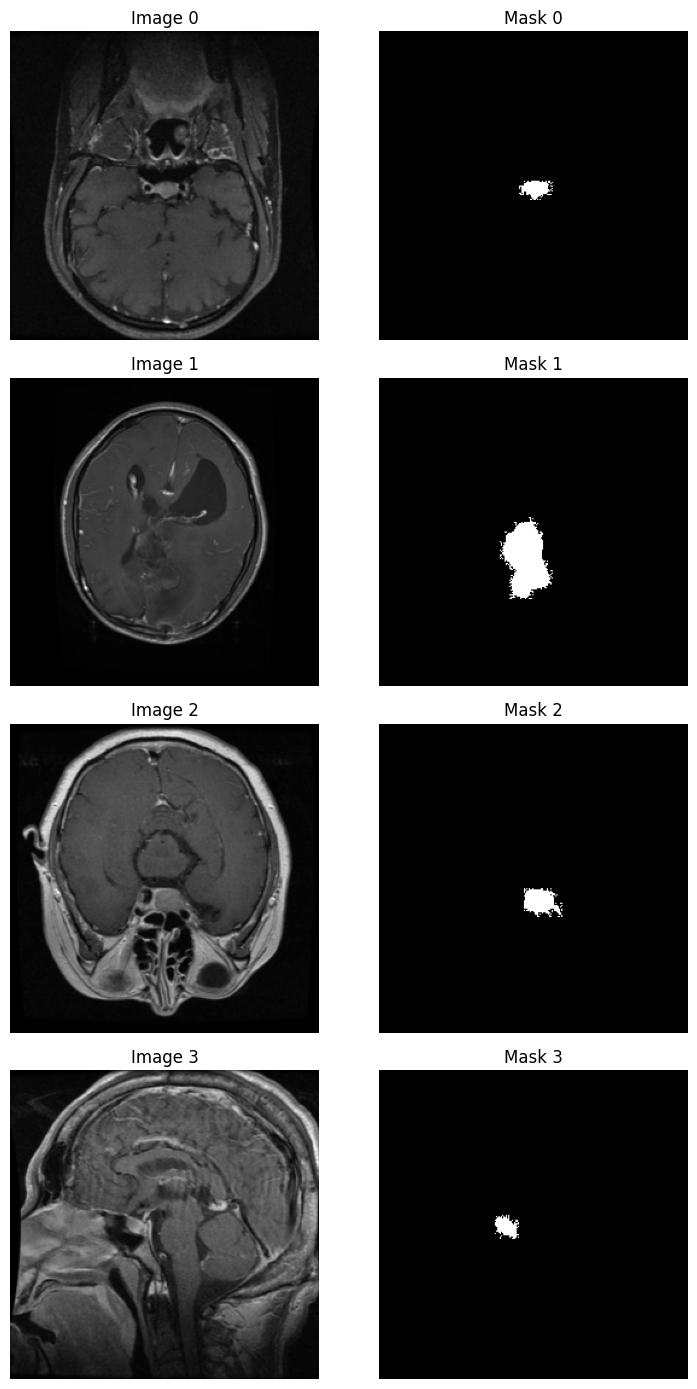

Images: torch.Size([8, 1, 256, 256]) | range [0.000, 0.969]
Masks:  torch.Size([8, 1, 256, 256])  | unique values: tensor([0., 1.])


In [15]:
# Visualize 4 image/mask pairs from train_loader
images, masks = next(iter(train_loader))

fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for i in range(4):
    axes[i, 0].imshow(images[i, 0].cpu(), cmap='gray')
    axes[i, 0].set_title(f"Image {i}"); axes[i, 0].axis('off')

    axes[i, 1].imshow(masks[i, 0].cpu(), cmap='gray')
    axes[i, 1].set_title(f"Mask {i}"); axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"Images: {images.shape} | range [{images.min():.3f}, {images.max():.3f}]")
print(f"Masks:  {masks.shape}  | unique values: {torch.unique(masks)}")


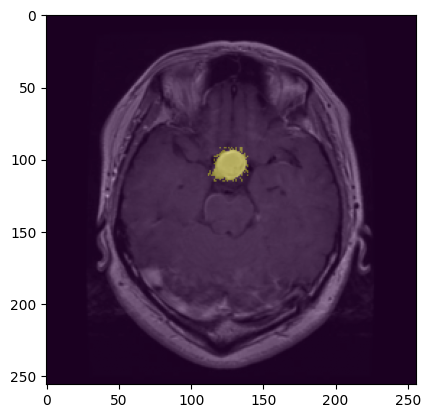

In [16]:
img , msk = train_dataset[0]
plt.imshow(img[0], cmap="gray")
plt.imshow(msk[0], alpha=0.4)

In [17]:
# U-Net. Adapted from milesial/Pytorch-UNet (GPL-3.0):
#   https://github.com/milesial/Pytorch-UNet/blob/master/unet/unet_parts.py
#   https://github.com/milesial/Pytorch-UNet/blob/master/unet/unet_model.py
# Edits: base 64->32, n_channels=1, n_classes=1, skips flag for ablation.

import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    """(convolution => [BN] => ReLU) * 2"""

    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class Down(nn.Module):
    """Downscaling with maxpool then double conv"""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(nn.Module):
    """Upscaling then double conv"""

    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(OutConv, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, n_channels=1, n_classes=1, base=32, bilinear=True, skips=True):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear
        self.skips = skips

        factor = 2 if bilinear else 1
        self.inc   = DoubleConv(n_channels, base)
        self.down1 = Down(base, base * 2)
        self.down2 = Down(base * 2, base * 4)
        self.down3 = Down(base * 4, base * 8)
        self.down4 = Down(base * 8, base * 16 // factor)
        self.up1   = Up(base * 16, base * 8 // factor, bilinear)
        self.up2   = Up(base * 8,  base * 4 // factor, bilinear)
        self.up3   = Up(base * 4,  base * 2 // factor, bilinear)
        self.up4   = Up(base * 2,  base, bilinear)
        self.outc  = OutConv(base, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # ablation: zero skip tensors (same shapes/params, no encoder info)
        if not self.skips:
            x1, x2, x3, x4 = (torch.zeros_like(t) for t in (x1, x2, x3, x4))

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)          # raw logits, no sigmoid


# shape check
if True:
    m = UNet()
    out = m(torch.randn(2, 1, 256, 256))
    assert out.shape == (2, 1, 256, 256), out.shape
    print("ok", sum(p.numel() for p in m.parameters()), "params")


ok 4317825 params


In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
print()

Using device: cuda



In [19]:

class SoftDiceLossV1(nn.Module):
    '''
    soft-dice loss, useful in binary segmentation
    '''
    def __init__(self,
                 p=1,
                 smooth=1):
        super(SoftDiceLossV1, self).__init__()
        self.p = p
        self.smooth = smooth

    def forward(self, logits, labels):
        probs = torch.sigmoid(logits)
        numer = (probs * labels).sum()
        denor = (probs.pow(self.p) + labels.pow(self.p)).sum()
        loss = 1. - (2 * numer + self.smooth) / (denor + self.smooth)
        return loss


bce_loss  = nn.BCEWithLogitsLoss()
dice_loss = SoftDiceLossV1()

def combo_loss(logits, target):
    return bce_loss(logits, target) + dice_loss(logits, target)


In [20]:
mask  = (torch.rand(2, 1, 256, 256) > 0.97).float()   # ~3% positive, like a tumor
good  = mask * 20 - 10                                 # confident-correct logits
bad   = torch.full_like(mask, -10.)                    # predicts all background

print("perfect  ", bce_loss(good, mask).item(), dice_loss(good, mask).item())
print("all-bg   ", bce_loss(bad,  mask).item(), dice_loss(bad,  mask).item())

perfect   4.5764976675854996e-05 0.0007514357566833496
all-bg    0.301788330078125 0.9996569752693176


In [21]:

from torch import Tensor

def dice_coeff(input: Tensor, target: Tensor, reduce_batch_first: bool = False, epsilon: float = 1e-6):
    # Average of Dice coefficient for all batches, or for a single mask
    assert input.size() == target.size()
    assert input.dim() == 3 or not reduce_batch_first

    sum_dim = (-1, -2) if input.dim() == 2 or not reduce_batch_first else (-1, -2, -3)

    inter = 2 * (input * target).sum(dim=sum_dim)
    sets_sum = input.sum(dim=sum_dim) + target.sum(dim=sum_dim)
    sets_sum = torch.where(sets_sum == 0, inter, sets_sum)

    dice = (inter + epsilon) / (sets_sum + epsilon)
    return dice.mean()


bce_loss = nn.BCEWithLogitsLoss()
dice_loss = SoftDiceLossV1()

def combo_loss(logits, target):
    return bce_loss(logits, target) + dice_loss(logits, target)



In [22]:
mask = (torch.rand(4, 1, 256, 256) > 0.97).float()
good = mask * 20 -10
bad = torch.full_like(mask, -10.)

print(dice_coeff(good, mask))
print(dice_coeff(bad, mask))

tensor(-0.0643)
tensor(0.0604)


In [23]:
def dice_iou(logits, target, eps=1e-6):
    pred = (torch.sigmoid(logits) > 0.5).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    dice = (2 * inter + eps) / (union + eps)
    return dice, dice / (2 - dice)

In [24]:
mask = (torch.rand(4, 1, 256, 256) > 0.97).float()
good = mask * 20 - 10
bad  = torch.full_like(mask, -10.)

d, i = dice_iou(good, mask)
assert d.mean() > 0.99 and i.mean() > 0.99, (d, i)

d, i = dice_iou(bad, mask)
assert d.mean() < 0.01 and i.mean() < 0.01, (d, i)

# cross-check against the milesial source
pred = (torch.sigmoid(good) > 0.5).float()
print(dice_iou(good, mask)[0].mean().item(),
      dice_coeff(pred, mask, reduce_batch_first=False).item())

print("metrics ok")


1.0 1.0
metrics ok


In [25]:


def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    running = 0.0
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction and loss
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        running += loss.item()
    return running / len(dataloader)


def test_loop(dataloader, model, loss_fn):
    model.eval()
    num_batches = len(dataloader)
    test_loss = 0
    dices, ious = [], []      : replaces `correct`

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()

            d, i = dice_iou(pred, y)         : replaces argmax accuracy
            dices.append(d)
            ious.append(i)

    test_loss /= num_batches
    return test_loss, torch.cat(dices).mean().item(), torch.cat(ious).mean().item()


In [26]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device {device}')

def run_experiment(loss_fn, skips = True, epochs=25, seed = 42, tag="bce"):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

  torch.backends.cudnn.benchmark = False
  torch.backends.cudnn.deterministic = True

  model = UNet(n_channels=1, n_classes=1, base=32, skips=skips)
  model.to(device=device)

  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

  train_losses, val_losses, val_dices, val_ious = [], [], [], []

  best = -1.0
  for t in range(epochs):
    tr = train_loop(train_loader, model, loss_fn , optimizer)
    vl, vd, vi = test_loop(valid_loader, model , loss_fn)

    train_losses.append(tr)
    val_losses.append(vl)
    val_dices.append(vd)
    val_ious.append(vi)

    if vd > best:
              best = vd
              torch.save(model.state_dict(), f"best_{tag}.pt")

    print(f"epoch {t+1:2d}  train {tr:.4f}  val {vl:.4f}  dice {vd:.4f}  iou {vi:.4f}")

  history = {"train_loss": train_losses, "val_loss": val_losses,
                "val_dice": val_dices, "val_iou": val_ious}
  return history, best

Using device cuda


In [27]:
hist_bce, best_bce_dice = run_experiment(bce_loss, epochs=25, tag="bce")

epoch  1  train 0.1501  val 0.0678  dice 0.2060  iou 0.1496
epoch  2  train 0.0510  val 0.0561  dice 0.4479  iou 0.3509
epoch  3  train 0.0405  val 0.0359  dice 0.5450  iou 0.4460
epoch  4  train 0.0341  val 0.0310  dice 0.5962  iou 0.5009
epoch  5  train 0.0298  val 0.0297  dice 0.6306  iou 0.5365
epoch  6  train 0.0260  val 0.0680  dice 0.1101  iou 0.0846
epoch  7  train 0.0244  val 0.0245  dice 0.6548  iou 0.5628
epoch  8  train 0.0222  val 0.0259  dice 0.6946  iou 0.5914
epoch  9  train 0.0211  val 0.0223  dice 0.7278  iou 0.6266
epoch 10  train 0.0202  val 0.0220  dice 0.7351  iou 0.6310
epoch 11  train 0.0201  val 0.0214  dice 0.7155  iou 0.6199
epoch 12  train 0.0186  val 0.0211  dice 0.6978  iou 0.6041
epoch 13  train 0.0180  val 0.0195  dice 0.7207  iou 0.6204
epoch 14  train 0.0189  val 0.0248  dice 0.6885  iou 0.6006
epoch 15  train 0.0170  val 0.0207  dice 0.7197  iou 0.6185
epoch 16  train 0.0169  val 0.0401  dice 0.5913  iou 0.5001
epoch 17  train 0.0180  val 0.0186  dice

In [28]:
hist_dice , best_dice_dice = run_experiment(dice_loss, epochs=25, tag="dice")
hist_combo , best_combo = run_experiment(combo_loss, epochs=25, tag="combo")



epoch  1  train 0.6679  val 0.4568  dice 0.4499  iou 0.3671
epoch  2  train 0.3857  val 0.3972  dice 0.5117  iou 0.4298
epoch  3  train 0.3462  val 0.4018  dice 0.5406  iou 0.4367
epoch  4  train 0.3192  val 0.3131  dice 0.6189  iou 0.5252
epoch  5  train 0.2989  val 0.3074  dice 0.6091  iou 0.5164
epoch  6  train 0.2868  val 0.3150  dice 0.6100  iou 0.5181
epoch  7  train 0.2685  val 0.2934  dice 0.6380  iou 0.5484
epoch  8  train 0.2734  val 0.2840  dice 0.6613  iou 0.5690
epoch  9  train 0.2548  val 0.2822  dice 0.6524  iou 0.5653
epoch 10  train 0.2524  val 0.2685  dice 0.6713  iou 0.5808
epoch 11  train 0.2510  val 0.2625  dice 0.6609  iou 0.5755
epoch 12  train 0.2408  val 0.2526  dice 0.6853  iou 0.5943
epoch 13  train 0.2400  val 0.2731  dice 0.6664  iou 0.5670
epoch 14  train 0.2400  val 0.2543  dice 0.6915  iou 0.5999
epoch 15  train 0.2390  val 0.2494  dice 0.6891  iou 0.5960
epoch 16  train 0.2390  val 0.2690  dice 0.6627  iou 0.5741
epoch 17  train 0.2255  val 0.2495  dice

In [29]:
histories = {
    'dice_loss_history': hist_dice,
    'combo_loss_history': hist_combo,
    "bce_loss_history": hist_bce,
}
torch.save(histories, '/kaggle/working/histories.pt')
print("saved", {k: len(v['val_dice']) for k, v in histories.items()})

saved {'dice_loss_history': 25, 'combo_loss_history': 25, 'bce_loss_history': 25}


In [30]:
print(len(hist_bce['train_loss']), len(hist_bce['val_dice']), max(hist_bce['val_dice']))

25 25 0.783311665058136


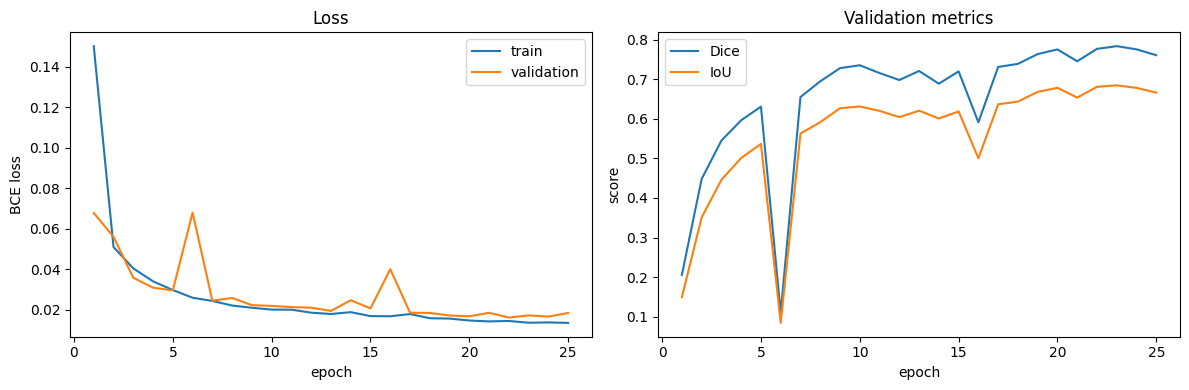

In [31]:
import matplotlib.pyplot as plt

# Access the data from the hist_bce dictionary
train_losses = hist_bce['train_loss']
val_losses = hist_bce['val_loss']
val_dices = hist_bce['val_dice']
val_ious = hist_bce['val_iou']

epochs = range(1, len(train_losses) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, train_losses, label="train")
ax1.plot(epochs, val_losses, label="validation")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss")
ax1.set_title("Loss"); ax1.legend()

ax2.plot(epochs, val_dices, label="Dice")
ax2.plot(epochs, val_ious, label="IoU")
ax2.set_xlabel("epoch"); ax2.set_ylabel("score")
ax2.set_title("Validation metrics"); ax2.legend()

plt.tight_layout()
plt.show()

In [32]:
# Summary using hist_bce keys
val_dices = hist_bce['val_dice']
val_ious = hist_bce['val_iou']

best = max(range(len(val_dices)), key=lambda k: val_dices[k])
print(f"best epoch {best+1}: dice {val_dices[best]:.4f}  iou {val_ious[best]:.4f}")
print(f"final epoch:  dice {val_dices[-1]:.4f}  iou {val_ious[-1]:.4f}")

best epoch 23: dice 0.7833  iou 0.6844
final epoch:  dice 0.7605  iou 0.6660


In [33]:
# Compare best val Dice across loss functions (single-run; treat small gaps as noise)
bests = {
    "BCE": max(hist_bce["val_dice"]),
    "Dice": max(hist_dice["val_dice"]),
    "BCE+Dice": max(hist_combo["val_dice"]),
}
for k, v in bests.items():
    print(f"{k:9s} {v:.4f}")
print(f"range: {max(bests.values()) - min(bests.values()):.4f}")
NOISE = 0.04  # gap smaller than this is treated as within run noise


pooled within-run sd (last 10 epochs): 0.0450
2 sigma                                 : 0.0899
simulated best-of-10 5-95 spread      : 0.0859

NOISE = 0.04
  BCE       0.7833
  Dice      0.7295
  BCE+Dice  0.7784
range across losses: 0.0538  -> a real difference


In [34]:
hist_noskip, best_noskip = run_experiment(bce_loss, skips=False, epochs=25, tag="noskip")

drop = best_bce_dice - best_noskip
print(f"skips   {best_bce_dice:.4f}")
print(f"no-skip {best_noskip:.4f}")
print(f"drop    {drop:.4f}   threshold {NOISE}")
print("VERDICT:", "skip connections help" if drop > NOISE else "within noise")


epoch  1  train 0.1511  val 0.0779  dice 0.3632  iou 0.2615
epoch  2  train 0.0498  val 0.0445  dice 0.4347  iou 0.3364
epoch  3  train 0.0381  val 0.0362  dice 0.5371  iou 0.4303
epoch  4  train 0.0324  val 0.0279  dice 0.5845  iou 0.4804
epoch  5  train 0.0290  val 0.0277  dice 0.6483  iou 0.5368
epoch  6  train 0.0263  val 0.0270  dice 0.6336  iou 0.5268
epoch  7  train 0.0252  val 0.0248  dice 0.6569  iou 0.5449
epoch  8  train 0.0230  val 0.0235  dice 0.6699  iou 0.5607
epoch  9  train 0.0220  val 0.0273  dice 0.6123  iou 0.4966
epoch 10  train 0.0217  val 0.0232  dice 0.6368  iou 0.5327
epoch 11  train 0.0207  val 0.0213  dice 0.6912  iou 0.5810
epoch 12  train 0.0202  val 0.0209  dice 0.7057  iou 0.5946
epoch 13  train 0.0197  val 0.0216  dice 0.7186  iou 0.6077
epoch 14  train 0.0197  val 0.0204  dice 0.7049  iou 0.5929
epoch 15  train 0.0188  val 0.0223  dice 0.7008  iou 0.5926
epoch 16  train 0.0179  val 0.0374  dice 0.4296  iou 0.3425
epoch 17  train 0.0179  val 0.0196  dice

In [35]:
torch.save({"noskip": hist_noskip}, "/kaggle/working/hist_noskip.pt")
print("saved", len(hist_noskip["val_dice"]), "epochs")

saved 25 epochs


BCE 25 [0.20595233142375946, 0.4478907585144043, 0.5449575781822205]
Dice 25 [0.44994649291038513, 0.5117208957672119, 0.5406409502029419]
BCE+Dice 25 [0.4316146969795227, 0.5300409197807312, 0.5157108902931213]
BCE no-skip 25 [0.3631722629070282, 0.43469926714897156, 0.537091076374054]


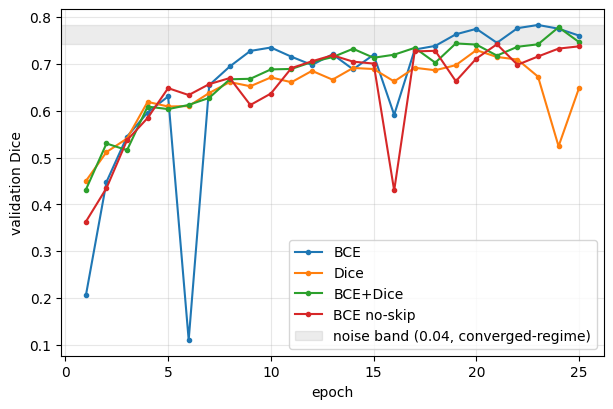

In [36]:
plt.ioff()
hists = {"BCE": hist_bce, "Dice": hist_dice, "BCE+Dice": hist_combo,
         "BCE no-skip": hist_noskip}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, h in hists.items():
    y = h["val_dice"]
    print(name, len(y), y[:3])          # must print 25 numbers, not 0
    ax.plot(range(1, len(y) + 1), y, marker="o", ms=3, label=name)

top = max(max(h["val_dice"]) for h in hists.values())
ax.axhspan(top - NOISE, top, color="grey", alpha=0.15, label=f"noise band ({NOISE}, converged-regime)")
ax.set_xlabel("epoch"); ax.set_ylabel("validation Dice"); ax.legend(); ax.grid(alpha=0.3)
plt.show()


In [37]:
model = UNet(n_channels=1, n_classes=1, base=32, skips=True)
model.load_state_dict(torch.load("best_bce.pt", map_location=device))
model.to(device).eval()

scores, imgs, gts, probs = [], [], [], []
with torch.no_grad():
    for X, y in valid_loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        d, _ = dice_iou(logits, y)
        scores.append(d.cpu()); imgs.append(X.cpu())
        gts.append(y.cpu());   probs.append(torch.sigmoid(logits).cpu())

scores = torch.cat(scores); imgs = torch.cat(imgs)
gts    = torch.cat(gts);    probs = torch.cat(probs)

print(f"n = {len(scores)}")
print(f"mean {scores.mean():.4f}   median {scores.median():.4f}")
print(f"min  {scores.min():.4f}    max    {scores.max():.4f}")
print(f"below 0.5: {(scores < 0.5).sum().item()} images")

n = 787
mean 0.7833   median 0.8613
min  0.0000    max    0.9720
below 0.5: 79 images


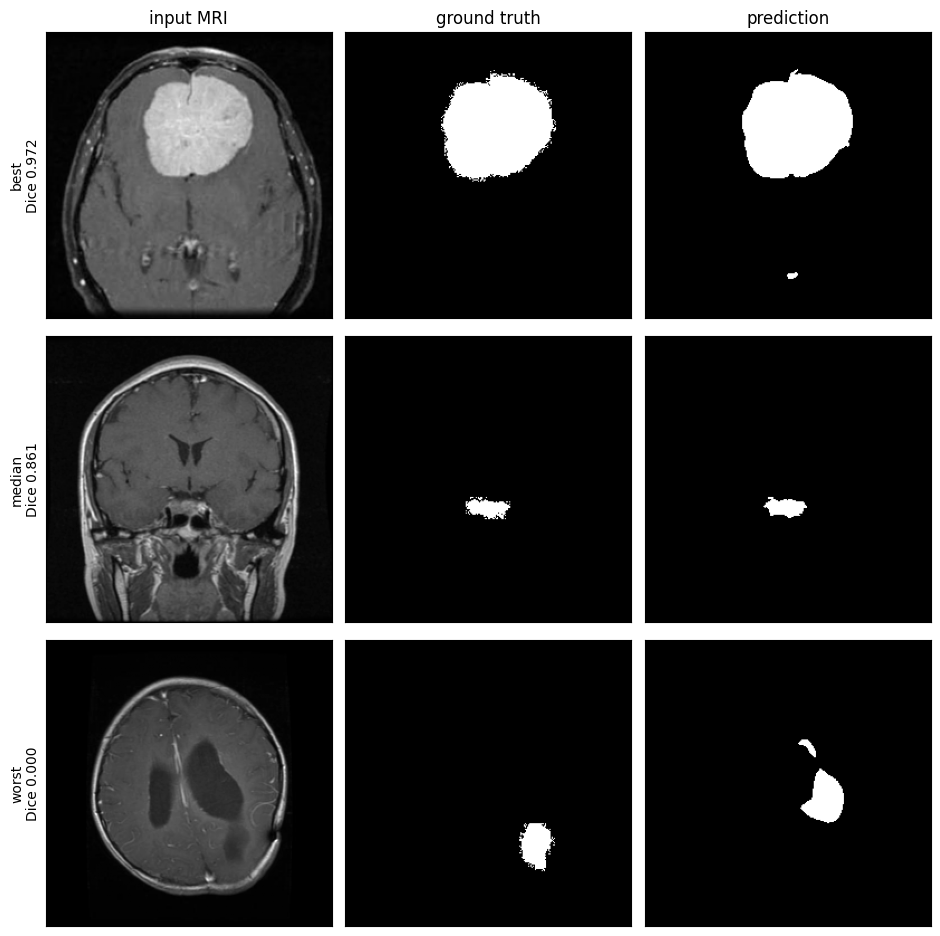

In [38]:
order = torch.argsort(scores)
picks = [(order[-1].item(), "best"),
         (order[len(order)//2].item(), "median"),
         (order[0].item(), "worst")]

fig, axes = plt.subplots(3, 3, figsize=(9.5, 9.5))
for r, (idx, label) in enumerate(picks):
    pred = (probs[idx, 0] > 0.5).float()
    axes[r, 0].imshow(imgs[idx, 0], cmap="gray")
    axes[r, 0].set_ylabel(f"{label}\nDice {scores[idx]:.3f}", fontsize=10)
    axes[r, 1].imshow(gts[idx, 0], cmap="gray")
    axes[r, 2].imshow(pred, cmap="gray")
    for c in range(3):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
for c, t in enumerate(["input MRI", "ground truth", "prediction"]):
    axes[0, c].set_title(t)
plt.tight_layout(); plt.show()

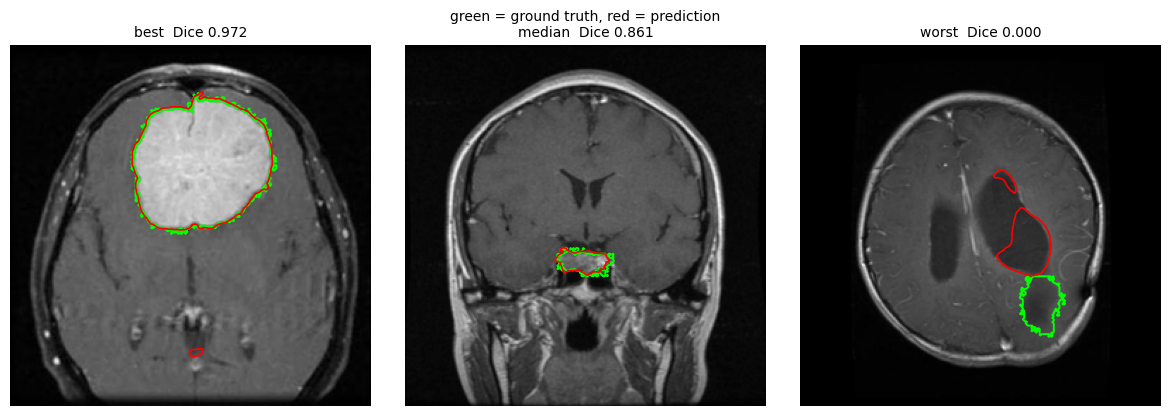

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (idx, label) in zip(axes, picks):
    ax.imshow(imgs[idx, 0], cmap="gray")
    ax.contour(gts[idx, 0],   levels=[0.5], colors="lime", linewidths=1.4)
    ax.contour(probs[idx, 0], levels=[0.5], colors="red",  linewidths=1.2)
    ax.set_title(f"{label}  Dice {scores[idx]:.3f}", fontsize=10)
    ax.axis("off")
fig.suptitle("green = ground truth, red = prediction", fontsize=10)
plt.tight_layout(); plt.show()

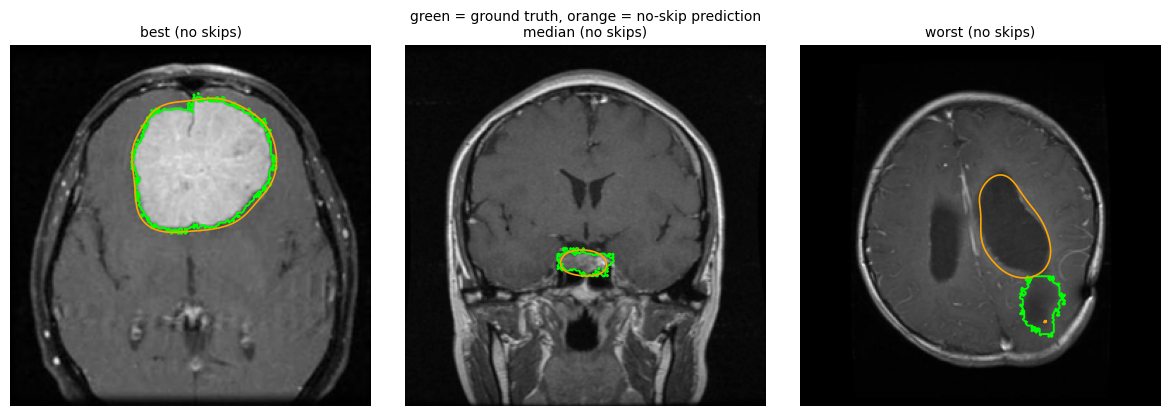

In [40]:
model_ns = UNet(n_channels=1, n_classes=1, base=32, skips=False)   # skips=False
model_ns.load_state_dict(torch.load("best_noskip.pt", map_location=device))
model_ns.to(device).eval()

with torch.no_grad():
    probs_ns = torch.sigmoid(model_ns(imgs[[i for i, _ in picks]].to(device))).cpu()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for k, (ax, (idx, label)) in enumerate(zip(axes, picks)):
    ax.imshow(imgs[idx, 0], cmap="gray")
    ax.contour(gts[idx, 0],    levels=[0.5], colors="lime",   linewidths=1.4)
    ax.contour(probs_ns[k, 0], levels=[0.5], colors="orange", linewidths=1.2)
    ax.set_title(f"{label} (no skips)", fontsize=10)
    ax.axis("off")
fig.suptitle("green = ground truth, orange = no-skip prediction", fontsize=10)
plt.tight_layout(); plt.show()

## Test-set evaluation

Evaluate the selected model once on the held-out test set (no further tuning).


In [41]:
test_img_paths  = {p.stem: p for p in test_images}
test_mask_paths = {p.stem: p for p in test_masks}
common_test = sorted(test_img_paths.keys() & test_mask_paths.keys())
test_pairs  = [(k, test_img_paths[k], test_mask_paths[k]) for k in common_test]

print(f"{len(test_images)} images, {len(test_masks)} masks -> {len(test_pairs)} pairs")
assert len(test_pairs) > 0

test_dataset = SegmentationDataset(test_pairs, transform=eval_transform)   # eval, no flips
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False,
                          num_workers=4, pin_memory=True)

860 images, 860 masks -> 860 pairs


In [42]:
def evaluate(ckpt, loss_fn, skips=True):
    m = UNet(n_channels=1, n_classes=1, base=32, skips=skips)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.to(device).eval()
    return test_loop(test_loader, m, loss_fn)

runs = [("BCE",         "best_bce.pt",    bce_loss,   True),
        ("Dice",        "best_dice.pt",   dice_loss,  True),
        ("BCE+Dice",    "best_combo.pt",  combo_loss, True),
        ("BCE no-skip", "best_noskip.pt", bce_loss,   False)]   # skips=False

print(f"{'model':12s} {'loss':>8s} {'Dice':>8s} {'IoU':>8s}")
test_results = {}
for name, ckpt, fn, sk in runs:
    try:
        loss, d, i = evaluate(ckpt, fn, skips=sk)
        test_results[name] = (d, i)
        print(f"{name:12s} {loss:8.4f} {d:8.4f} {i:8.4f}")
    except FileNotFoundError:
        print(f"{name:12s}   [checkpoint not found]")

print()
print(f"BCE validation Dice {best_bce_dice:.4f}")
if "BCE" in test_results:
    print(f"BCE test       Dice {test_results['BCE'][0]:.4f}")
    print(f"gap                 {best_bce_dice - test_results['BCE'][0]:+.4f}")

model            loss     Dice      IoU
BCE            0.0176   0.7913   0.6975
Dice           0.2169   0.7424   0.6485
BCE+Dice       0.2105   0.7927   0.7002
BCE no-skip    0.0200   0.7533   0.6455

BCE validation Dice 0.7833
BCE test       Dice 0.7913
gap                 -0.0080


## Q1 — What do skip connections contribute?

Ablation: zero the encoder skip maps in `forward` (same shapes and parameter count; only the information flow changes).

Results (BCE): with skips best val Dice ≈ 0.78; without skips ≈ 0.74 (drop ≈ 0.04). Test set moves in the same direction (~0.79 vs ~0.75).

Interpretation: four max-pools shrink the map to 16×16, so the bottleneck keeps “what/roughly where” but loses fine edges. Skips restore high-resolution features to the decoder. Without them the model still finds tumours but boundaries get worse.


## Q2 — Dice and IoU both measure overlap. Why can accuracy be high while Dice is low?

$$
\mathrm{Dice}=\frac{2\,TP}{2\,TP+FP+FN},\quad
\mathrm{IoU}=\frac{TP}{TP+FP+FN},\quad
\mathrm{Acc}=\frac{TP+TN}{TP+TN+FP+FN}
$$

Only accuracy uses TN. Tumours are small, so predicting all background can look >95% accurate while Dice/IoU are ~0. Use Dice/IoU for segmentation.

Relation: $\mathrm{IoU}=\mathrm{Dice}/(2-\mathrm{Dice})$ (same ranking). Metrics are averaged per image so large tumours do not dominate.


## Q3 — Must geometric augmentation match on image and mask?

Yes. The mask is labels in the image coordinate frame. Augmenting only one side misaligns supervision.

Use one `v2.Compose` on `tv_tensors.Image` + `tv_tensors.Mask` so random params are shared. After bilinear resize, re-binarise the mask (`mask > 0`). Apply geometric aug only in the train transform.


## Q4 — The no_tumor class has no mask. How was it handled?

`segmentation_task` only ships masks for tumour classes. Pairing by stem intersection drops unmasked slices automatically:

```python
common_keys = sorted(IMAGE_DIR_Train_paths.keys() & MASKS_DIR_Train_paths.keys())
```

No extra filter. Empty-ground-truth Dice is awkward (0/0); keeping segmentation on masked (tumour) cases avoids that. Classification vs segmentation are separate BRISC splits.
